# Ethereum On-Chain Analytics

Consolidated portfolio notebook combining the one-day transaction analysis and the 30-day gas-price analysis. Saved outputs and chart images from the source notebooks are retained where applicable.


## Part 1 — Ethereum Transaction Analysis (October 28, 2026)

This section contains the original AWS S3 / DuckDB transaction analysis and Figures 1–4.


In [ ]:
import duckdb

print("DuckDB version:", duckdb.__version__)

DuckDB version: 1.4.5


In [ ]:
import duckdb

# Create DuckDB connection
con = duckdb.connect()

# Load S3 support
con.execute("LOAD httpfs;")

# Configure AWS region
con.execute("SET s3_region = 'us-east-2';")

print("DuckDB:", duckdb.__version__)
print("S3 extension: Loaded")
print("AWS region: us-east-2")
print("Ethereum analytics environment ready!")

DuckDB: 1.4.5
S3 extension: Loaded
AWS region: us-east-2
Ethereum analytics environment ready!


In [ ]:
url = "https://aws-public-blockchain.s3.us-east-2.amazonaws.com/v1.0/eth/transactions/date=2026-10-28/part-00000-cc47f3aa-ac0b-41f2-91b4-9b144e7cf1a9-c000.snappy.parquet"

result = con.execute(f"""
    SELECT
        block_number,
        transaction_index,
        from_address,
        to_address,
        receipt_status
    FROM read_parquet('{url}')
    LIMIT 5
""").df()

result

,block_number,transaction_index,from_address,to_address,receipt_status
0,26287496,0,0x2252f216f4a494a87025123425181ca1bb754fb8,0x0000000aa232009084bd71a5797d089aa4edfad4,1
1,26287496,1,0x46187698198fa02f071d999347fe0db2ee79934b,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1
2,26287496,2,0x8316174a0f13c9aae7f2409a19ebd8ec8c69aaf4,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1
3,26287496,3,0x81dc771e308c76c3e06f635abed7fb24830fb824,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1
4,26287496,4,0xd2700e7bbe0a8af6d6c5b3f61d27855daa425a53,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1


In [ ]:
schema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_parquet('{url}')
""").df()

schema

,column_name,column_type,null,key,default,extra
0,gas,BIGINT,YES,None,None,None
1,hash,VARCHAR,YES,None,None,None
2,input,VARCHAR,YES,None,None,None
3,nonce,BIGINT,YES,None,None,None
4,value,DOUBLE,YES,None,None,None
5,block_number,BIGINT,YES,None,None,None
6,block_hash,VARCHAR,YES,None,None,None
7,transaction_index,BIGINT,YES,None,None,None
8,from_address,VARCHAR,YES,None,None,None
9,to_address,VARCHAR,YES,None,None,None


In [ ]:
summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 1
        ) AS successful_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE receipt_status = 1
            ) / COUNT(*), 2
        ) AS success_rate_pct
    FROM read_parquet('{url}')
""").df()

summary

,total_transactions,successful_transactions,failed_transactions,success_rate_pct
0,1996106,1971694,24412,98.78


In [ ]:
test = con.execute(f"""
    SELECT COUNT(*)
    FROM read_parquet('{url}')
    LIMIT 1
""").fetchone()

print(test)

(1996106,)


In [ ]:
hourly = con.execute(f"""
    SELECT
        EXTRACT(HOUR FROM block_timestamp) AS hour,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions
    FROM read_parquet('{url}')
    GROUP BY hour
    ORDER BY hour
""").df()

hourly

,hour,total_transactions,failed_transactions
0,0,139247,1837
1,1,94675,1055
2,2,68581,1750
3,3,63719,1179
4,4,62349,930
5,5,57211,807
6,6,58863,679
7,7,83311,798
8,8,73797,914
9,9,132144,830


In [ ]:
hourly["failure_rate_pct"] = (
    hourly["failed_transactions"]
    / hourly["total_transactions"]
    * 100
).round(2)

hourly

,hour,total_transactions,failed_transactions,failure_rate_pct
0,0,139247,1837,1.32
1,1,94675,1055,1.11
2,2,68581,1750,2.55
3,3,63719,1179,1.85
4,4,62349,930,1.49
5,5,57211,807,1.41
6,6,58863,679,1.15
7,7,83311,798,0.96
8,8,73797,914,1.24
9,9,132144,830,0.63


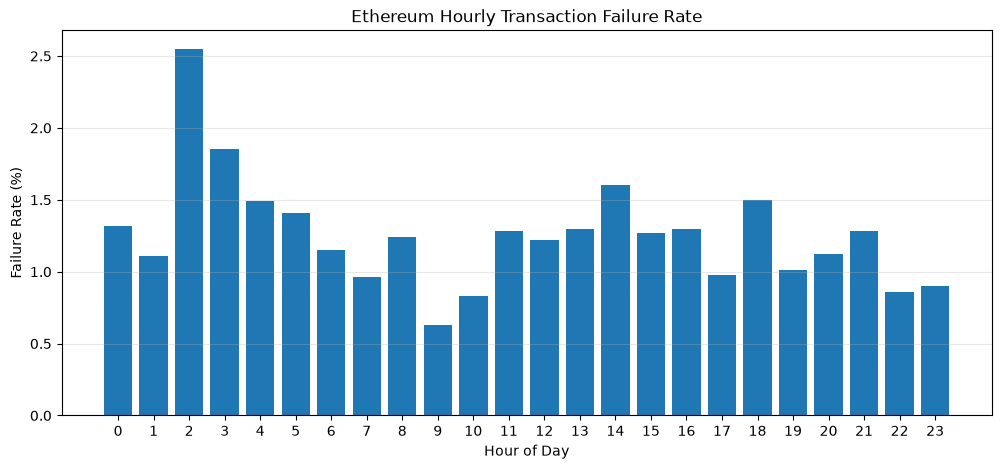

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    hourly["hour"],
    hourly["failure_rate_pct"]
)

plt.title("Ethereum Hourly Transaction Failure Rate")
plt.xlabel("Hour of Day")
plt.ylabel("Failure Rate (%)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.savefig("visualizations/01_hourly_failure_rate.png",
            dpi=300, bbox_inches="tight")
plt.show()

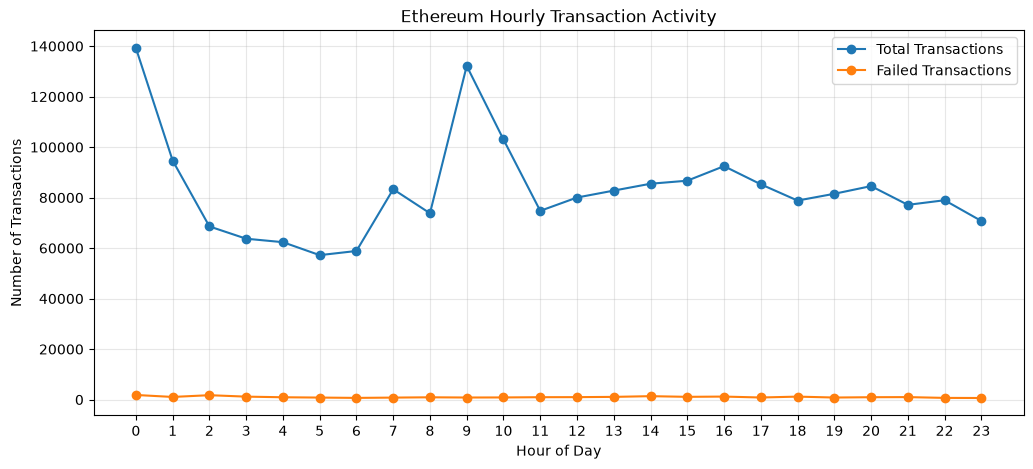

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly["hour"],
    hourly["total_transactions"],
    marker="o",
    label="Total Transactions"
)

plt.plot(
    hourly["hour"],
    hourly["failed_transactions"],
    marker="o",
    label="Failed Transactions"
)

plt.title("Ethereum Hourly Transaction Activity")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("visualizations/02_hourly_activity.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
tx_types = con.execute(f"""
    SELECT
        transaction_type,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS transaction_share_pct
    FROM read_parquet('{url}')
    GROUP BY transaction_type
    ORDER BY transaction_type
""").df()

tx_types

,transaction_type,total_transactions,failed_transactions,transaction_share_pct
0,0,424874,4855,21.29
1,1,495,5,0.02
2,2,1528571,18925,76.58
3,3,16498,0,0.83
4,4,25668,627,1.29


In [ ]:
tx_types["failure_rate_pct"] = (
    tx_types["failed_transactions"]
    / tx_types["total_transactions"]
    * 100
).round(2)

tx_types

,transaction_type,total_transactions,failed_transactions,transaction_share_pct,failure_rate_pct
0,0,424874,4855,21.29,1.14
1,1,495,5,0.02,1.01
2,2,1528571,18925,76.58,1.24
3,3,16498,0,0.83,0.00
4,4,25668,627,1.29,2.44


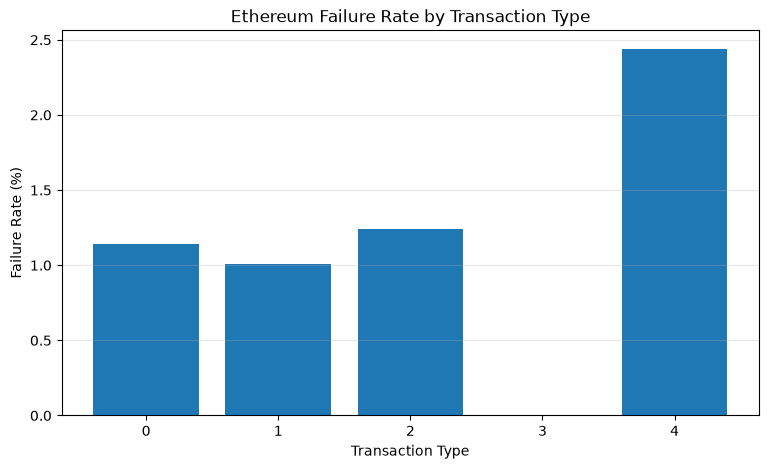

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    tx_types["transaction_type"].astype(str),
    tx_types["failure_rate_pct"]
)

plt.title("Ethereum Failure Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Failure Rate (%)")
plt.grid(axis="y", alpha=0.3)

plt.savefig("visualizations/03_failure_rate_by_type.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
gas_analysis = con.execute(f"""
    SELECT
        CASE
            WHEN receipt_status = 1 THEN 'Successful'
            WHEN receipt_status = 0 THEN 'Failed'
            ELSE 'Unknown'
        END AS transaction_status,
        COUNT(*) AS total_transactions,
        ROUND(AVG(receipt_gas_used), 2) AS avg_gas_used,
        ROUND(AVG(receipt_effective_gas_price) / 1e9, 4)
            AS avg_gas_price_gwei,
        ROUND(
            SUM(
                receipt_gas_used * receipt_effective_gas_price
            ) / 1e18,
            4
        ) AS estimated_fees_eth
    FROM read_parquet('{url}')
    GROUP BY transaction_status
    ORDER BY transaction_status
""").df()

gas_analysis

,transaction_status,total_transactions,avg_gas_used,avg_gas_price_gwei,estimated_fees_eth
0,Failed,24412,144501.51,0.4794,1.2745
1,Successful,1971694,108875.65,0.6166,109.1463


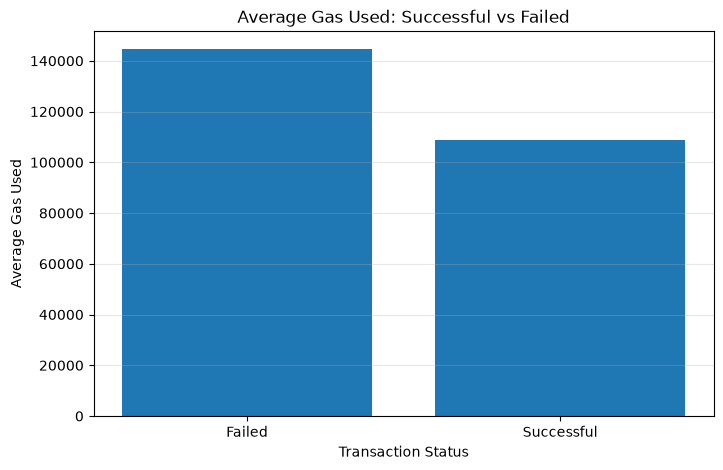

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    gas_analysis["transaction_status"],
    gas_analysis["avg_gas_used"]
)

plt.title("Average Gas Used: Successful vs Failed")
plt.xlabel("Transaction Status")
plt.ylabel("Average Gas Used")
plt.grid(axis="y", alpha=0.3)

plt.savefig("visualizations/04_gas_used.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
total_fees = gas_analysis["estimated_fees_eth"].sum()

total_transactions = gas_analysis["total_transactions"].sum()

average_fee = total_fees / total_transactions

print(f"Total estimated fees: {total_fees:.4f} ETH")
print(f"Total transactions: {total_transactions:,}")
print(f"Average fee: {average_fee:.10f} ETH")

Total estimated fees: 110.4208 ETH
Total transactions: 1,996,106
Average fee: 0.0000553181 ETH


In [ ]:
hourly.to_csv("ethereum_hourly_analysis.csv", index=False)

tx_types.to_csv("ethereum_transaction_types.csv", index=False)

gas_analysis.to_csv("ethereum_gas_analysis.csv", index=False)

print("Three analysis files saved successfully.")

Three analysis files saved successfully.


In [ ]:
import os

files = [
    "ethereum_hourly_analysis.csv",
    "ethereum_transaction_types.csv",
    "ethereum_gas_analysis.csv"
]

for file in files:
    print(file, "—", os.path.getsize(file), "bytes")

ethereum_hourly_analysis.csv — 515 bytes
ethereum_transaction_types.csv — 212 bytes
ethereum_gas_analysis.csv — 174 bytes


In [ ]:
import os

print(os.getcwd())

C:\Users\AL MUZDAHAR COMPUTER\DataScience\Ethereum_OnChain_Analytics


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create a folder for visualizations
output_dir = Path("visualizations")
output_dir.mkdir(exist_ok=True)

# Save all currently open charts
for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        output_dir / f"ethereum_analysis_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Charts saved:", len(plt.get_fignums()))
print("Folder:", output_dir.resolve())

Charts saved: 0
Folder: C:\Users\AL MUZDAHAR COMPUTER\DataScience\Ethereum_OnChain_Analytics\visualizations


In [ ]:
from pathlib import Path

Path("visualizations/01_hourly_failure_rate.png").exists()

True

In [ ]:
from pathlib import Path

for file in sorted(Path("visualizations").glob("*.png")):
    print(file.name, "-", round(file.stat().st_size / 1024, 1), "KB")

01_hourly_failure_rate.png - 74.8 KB
02_hourly_activity.png - 163.6 KB
03_failure_rate_by_type.png - 57.8 KB
04_gas_used.png - 66.9 KB


## Part 2 — Ethereum 30-Day Gas Analysis (October 1–30, 2026)

This section contains the 30-day processing, summary statistics, gas-price outlier analysis, fee-contribution analysis, and Figure 5.


In [ ]:
# Import libraries and check DuckDB
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("DuckDB version:", duckdb.__version__)
print("Pandas version:", pd.__version__)

DuckDB version: 1.4.5
Pandas version: 3.1.0


In [ ]:
# Connect to the public Ethereum dataset
# This enables DuckDB to read Parquet files directly from AWS S3
con = duckdb.connect()

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

print("HTTPFS extension loaded successfully.")

HTTPFS extension loaded successfully.


In [ ]:
# Check available October 2026 data
files = con.execute("""
    SELECT file
    FROM glob(
        's3://aws-public-blockchain/v1.0/eth/transactions/date=2026-10-*/part-*.parquet'
    )
    ORDER BY file
""").df()

print("Available Parquet files:", len(files))
display(files.head(10))

Available Parquet files: 31


,file
0,s3://aws-public-blockchain/v1.0/eth/transactio...
1,s3://aws-public-blockchain/v1.0/eth/transactio...
2,s3://aws-public-blockchain/v1.0/eth/transactio...
3,s3://aws-public-blockchain/v1.0/eth/transactio...
4,s3://aws-public-blockchain/v1.0/eth/transactio...
5,s3://aws-public-blockchain/v1.0/eth/transactio...
6,s3://aws-public-blockchain/v1.0/eth/transactio...
7,s3://aws-public-blockchain/v1.0/eth/transactio...
8,s3://aws-public-blockchain/v1.0/eth/transactio...
9,s3://aws-public-blockchain/v1.0/eth/transactio...


In [ ]:
# Extract and check the dates
files["date"] = files["file"].str.extract(r"date=(\d{4}-\d{2}-\d{2})")

print("Number of distinct dates:", files["date"].nunique())
print("First date:", files["date"].min())
print("Last date:", files["date"].max())

display(files[["date"]])

Number of distinct dates: 31
First date: 2026-10-01
Last date: 2026-10-31


,date
0,2026-10-01
1,2026-10-02
2,2026-10-03
3,2026-10-04
4,2026-10-05
5,2026-10-06
6,2026-10-07
7,2026-10-08
8,2026-10-09
9,2026-10-10


In [ ]:
# Create the ordered list of daily Parquet file paths
file_list = files["file"].tolist()
print("Parquet files ready:", len(file_list))

In [ ]:
print(con.execute("SELECT 1").fetchone())

(1,)


In [ ]:
print(files.loc[0, "file"])

s3://aws-public-blockchain/v1.0/eth/transactions/date=2026-10-01/part-00000-5917a3a9-ea72-4dc9-bf34-0fe0c149065a-c000.snappy.parquet


In [ ]:
file_info = con.execute("""
    SELECT *
    FROM parquet_file_metadata(?)
""", [files.loc[0, "file"]]).df()

display(file_info)

,file_name,created_by,num_rows,num_row_groups,format_version,encryption_algorithm,footer_signing_key_metadata,file_size_bytes,footer_size
0,s3://aws-public-blockchain/v1.0/eth/transactio...,parquet-mr version 1.10.1 (build 65f31597b18a0...,2036041,7,1,None,None,837720873,21297


In [ ]:
# inspect column metadata
schema_info = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_parquet(?)
""", [files.loc[0, "file"]]).df()

display(schema_info)

,column_name,column_type,null,key,default,extra
0,gas,BIGINT,YES,None,None,None
1,hash,VARCHAR,YES,None,None,None
2,input,VARCHAR,YES,None,None,None
3,nonce,BIGINT,YES,None,None,None
4,value,DOUBLE,YES,None,None,None
5,block_number,BIGINT,YES,None,None,None
6,block_hash,VARCHAR,YES,None,None,None
7,transaction_index,BIGINT,YES,None,None,None
8,from_address,VARCHAR,YES,None,None,None
9,to_address,VARCHAR,YES,None,None,None


In [ ]:
# Test a lightweight query
test_gas = con.execute("""
    SELECT
        date,
        COUNT(*) AS total_transactions,
        ROUND(AVG(receipt_gas_used), 2) AS avg_gas_used,
        ROUND(AVG(receipt_effective_gas_price) / 1e9, 4) AS avg_gas_price_gwei
    FROM read_parquet(?)
    WHERE receipt_status = 1
    GROUP BY date
""", [files.loc[0, "file"]]).df()

display(test_gas)

,date,total_transactions,avg_gas_used,avg_gas_price_gwei
0,2026-10-01,2012854,106096.92,1.3238


In [ ]:
# Calculate total fees for October 1
test_fees = con.execute("""
    SELECT
        date,
        ROUND(
            SUM(
                CAST(receipt_gas_used AS HUGEINT)
                * CAST(receipt_effective_gas_price AS HUGEINT)
            ) / 1e18,
            6
        ) AS total_fees_eth
    FROM read_parquet(?)
    WHERE receipt_status = 1
    GROUP BY date
""", [files.loc[0, "file"]]).df()

display(test_fees)

,date,total_fees_eth
0,2026-10-01,284.891764


In [ ]:
# Combine the calculations
test_daily_gas = con.execute("""
    SELECT
        date,
        ROUND(AVG(receipt_gas_used), 2) AS avg_gas_used,
        ROUND(AVG(receipt_effective_gas_price) / 1e9, 4) AS avg_gas_price_gwei,
        ROUND(
            SUM(
                CAST(receipt_gas_used AS HUGEINT)
                * CAST(receipt_effective_gas_price AS HUGEINT)
            ) / 1e18,
            6
        ) AS total_fees_eth
    FROM read_parquet(?)
    WHERE receipt_status = 1
    GROUP BY date
""", [files.loc[0, "file"]]).df()

display(test_daily_gas)

,date,avg_gas_used,avg_gas_price_gwei,total_fees_eth
0,2026-10-01,106096.92,1.3238,284.891764


In [ ]:
print("Files available:", len(file_list))
print("First date:", files.loc[0, "date"])
print("Last date:", files.loc[29, "date"])

Files available: 30
First date: 2026-10-01
Last date: 2026-10-30


In [ ]:
# Create a permanent checkpoint
from pathlib import Path

checkpoint_file = Path("ethereum_daily_gas_checkpoint.csv")

print("Checkpoint location:", checkpoint_file.resolve())
print("Already exists:", checkpoint_file.exists())

Checkpoint location: C:\Users\AL MUZDAHAR COMPUTER\DataScience\Ethereum_OnChain_Analytics\ethereum_daily_gas_checkpoint.csv
Already exists: False


In [ ]:
# Prepare a reliable processing function
import time

def process_daily_gas(file):
    for attempt in range(3):
        try:
            result = con.execute("""
                SELECT
                    date,
                    ROUND(AVG(receipt_gas_used), 2) AS avg_gas_used,
                    ROUND(AVG(receipt_effective_gas_price) / 1e9, 4) AS avg_gas_price_gwei,
                    ROUND(
                        SUM(
                            CAST(receipt_gas_used AS HUGEINT)
                            * CAST(receipt_effective_gas_price AS HUGEINT)
                        ) / 1e18,
                        6
                    ) AS total_fees_eth
                FROM read_parquet(?)
                WHERE receipt_status = 1
                GROUP BY date
            """, [file]).df()

            return result

        except Exception as e:
            print(f"Attempt {attempt + 1} failed: {e}")

            if attempt < 2:
                time.sleep(5)
            else:
                raise

In [ ]:
# test the function on October 1 only
test_result = process_daily_gas(file_list[0])
display(test_result)

,date,avg_gas_used,avg_gas_price_gwei,total_fees_eth
0,2026-10-01,106096.92,1.3238,284.891764


In [ ]:
# Initialize the checkpoint
# This creates an empty CSV that we'll update after every successful day.
daily_gas = pd.DataFrame(columns=[
    "date",
    "avg_gas_used",
    "avg_gas_price_gwei",
    "total_fees_eth"
])

daily_gas.to_csv(checkpoint_file, index=False)

print("Checkpoint created:", checkpoint_file.exists())

Checkpoint created: True


In [ ]:
# Process October 1 and save it
daily_gas = process_daily_gas(file_list[0])

daily_gas.to_csv(checkpoint_file, index=False)

print("Saved:", len(daily_gas), "day")
display(daily_gas)

Saved: 1 day


,date,avg_gas_used,avg_gas_price_gwei,total_fees_eth
0,2026-10-01,106096.92,1.3238,284.891764


In [ ]:
## Process the remaining 29 days
# Process one day at a time.
# Save the CSV immediately after each successful day.
# Stop if all three retry attempts fail, without losing previous results.
import time

for file in file_list:
    day = file.split("date=")[1][:10]

    saved_dates = set(
        pd.read_csv(checkpoint_file)["date"].astype(str)
    )

    if day in saved_dates:
        continue

    print(f"Processing {day}...")

    try:
        result = process_daily_gas(file)

        existing = pd.read_csv(checkpoint_file)
        updated = pd.concat([existing, result], ignore_index=True)

        updated.to_csv(checkpoint_file, index=False)

        print(f"Saved {day} successfully.")

    except Exception as e:
        print(f"Stopped at {day}: {e}")
        break

daily_gas = pd.read_csv(checkpoint_file)
print("Total completed days:", len(daily_gas))

Processing 2026-10-02...
Saved 2026-10-02 successfully.
Processing 2026-10-03...
Saved 2026-10-03 successfully.
Processing 2026-10-04...
Saved 2026-10-04 successfully.
Processing 2026-10-05...
Saved 2026-10-05 successfully.
Processing 2026-10-06...
Saved 2026-10-06 successfully.
Processing 2026-10-07...
Attempt 1 failed: IO Error: SSL connection failed error for HTTP HEAD to 'https://aws-public-blockchain.s3.amazonaws.com/v1.0/eth/transactions/date%3D2026-10-07/part-00000-fe3d885d-d28d-49dc-9e56-d3670eab98a9-c000.snappy.parquet'

LINE 13:                 FROM read_parquet(?)
                              ^
Attempt 2 failed: IO Error: SSL connection failed error for HTTP HEAD to 'https://aws-public-blockchain.s3.amazonaws.com/v1.0/eth/transactions/date%3D2026-10-07/part-00000-fe3d885d-d28d-49dc-9e56-d3670eab98a9-c000.snappy.parquet'

LINE 13:                 FROM read_parquet(?)
                              ^
Saved 2026-10-07 successfully.
Processing 2026-10-08...
Saved 2026-10-08 succ

In [ ]:
daily_gas["date"] = pd.to_datetime(
    daily_gas["date"],
    format="mixed"
)

In [ ]:
print(daily_gas["date"].head())

0   2026-10-01
1   2026-10-02
2   2026-10-03
3   2026-10-04
4   2026-10-05
Name: date, dtype: datetime64[us]


In [ ]:
# verification
daily_gas = daily_gas.sort_values("date").reset_index(drop=True)

print("Number of days:", len(daily_gas))
print("First date:", daily_gas["date"].min())
print("Last date:", daily_gas["date"].max())
print("Missing values:\n", daily_gas.isnull().sum())

display(daily_gas)

Number of days: 30
First date: 2026-10-01 00:00:00
Last date: 2026-10-30 00:00:00
Missing values:
 date                  0
avg_gas_used          0
avg_gas_price_gwei    0
total_fees_eth        0
dtype: int64


,date,avg_gas_used,avg_gas_price_gwei,total_fees_eth
0,2026-10-01,106096.92,1.3238,284.891764
1,2026-10-02,115174.52,0.9656,178.203337
2,2026-10-03,139248.34,0.6740,97.922999
3,2026-10-04,142159.00,0.8037,139.806025
4,2026-10-05,121737.27,1.3320,263.945640
5,2026-10-06,110158.62,1.3251,260.790372
6,2026-10-07,109870.62,1.5089,317.576962
7,2026-10-08,117448.37,1.9746,379.512801
8,2026-10-09,120079.71,0.8666,151.047334
9,2026-10-10,132410.36,0.6404,108.515763


In [ ]:
# calculate the 30-day summary statistics
print("30-DAY SUMMARY")
display(
    daily_gas[
        ["avg_gas_used", "avg_gas_price_gwei", "total_fees_eth"]
    ].describe().round(4)
)

print("Highest daily gas price:")
display(
    daily_gas.loc[
        daily_gas["avg_gas_price_gwei"].idxmax()
    ]
)

print("Highest daily total fees:")
display(
    daily_gas.loc[
        daily_gas["total_fees_eth"].idxmax()
    ]
)

30-DAY SUMMARY


,avg_gas_used,avg_gas_price_gwei,total_fees_eth
count,30.0000,30.0000,30.0000
mean,121883.6033,1.2226,305.5432
std,10528.0245,1.3922,567.8171
min,106096.9200,0.5486,71.7370
25%,115009.4300,0.6662,107.8663
50%,119765.2950,0.8574,145.4267
75%,125767.2300,1.1521,187.8717
max,142159.0000,7.9519,2695.3212


Highest daily gas price:


date                  2026-10-29 00:00:00
avg_gas_used                    122884.15
avg_gas_price_gwei                 7.9519
total_fees_eth                2695.321186
Name: 28, dtype: object

Highest daily total fees:


date                  2026-10-29 00:00:00
avg_gas_used                    122884.15
avg_gas_price_gwei                 7.9519
total_fees_eth                2695.321186
Name: 28, dtype: object

In [ ]:
check_spikes = con.execute("""
    SELECT
        date,
        COUNT(*) AS successful_transactions,
        ROUND(AVG(receipt_gas_used), 2) AS avg_gas_used,
        ROUND(AVG(receipt_effective_gas_price) / 1e9, 4) AS avg_gas_price_gwei,
        ROUND(MEDIAN(receipt_effective_gas_price) / 1e9, 4) AS median_gas_price_gwei,
        ROUND(QUANTILE_CONT(receipt_effective_gas_price, 0.95) / 1e9, 4) AS p95_gas_price_gwei,
        ROUND(MAX(receipt_effective_gas_price) / 1e9, 4) AS max_gas_price_gwei,
        ROUND(
            SUM(
                CAST(receipt_gas_used AS HUGEINT)
                * CAST(receipt_effective_gas_price AS HUGEINT)
            ) / 1e18,
            6
        ) AS total_fees_eth
    FROM read_parquet(?)
    WHERE receipt_status = 1
    GROUP BY date
    ORDER BY date
""", [[file_list[28], file_list[29]]]).df()

display(check_spikes)

,date,successful_transactions,avg_gas_used,avg_gas_price_gwei,median_gas_price_gwei,p95_gas_price_gwei,max_gas_price_gwei,total_fees_eth
0,2026-10-29,1730067,122884.15,7.9519,0.2946,36.2335,82736.7709,2695.321186
1,2026-10-30,1850158,113018.47,3.4626,0.7327,6.8741,128567.5226,2003.922235


In [ ]:
import time

for attempt in range(3):
    try:
        top_gas_prices = con.execute("""
            SELECT
                date,
                hash,
                receipt_gas_used,
                ROUND(receipt_effective_gas_price / 1e9, 4) AS gas_price_gwei,
                ROUND(
                    CAST(receipt_gas_used AS HUGEINT)
                    * CAST(receipt_effective_gas_price AS HUGEINT) / 1e18,
                    6
                ) AS transaction_fee_eth
            FROM read_parquet(?)
            WHERE receipt_status = 1
            QUALIFY ROW_NUMBER() OVER (
                PARTITION BY date
                ORDER BY receipt_effective_gas_price DESC
            ) <= 10
            ORDER BY date, gas_price_gwei DESC
        """, [[file_list[28], file_list[29]]]).df()

        print("Query successful.")
        display(top_gas_prices)
        break

    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")
        if attempt < 2:
            time.sleep(10)

Query successful.


,date,hash,receipt_gas_used,gas_price_gwei,transaction_fee_eth
0,2026-10-29,0xc8f80b6f1ce70ead4b6d5711d20802664b8dc63111af...,107766,82736.7709,8.916211
1,2026-10-29,0x9929eca671e0759bbca93e5c69db92f926c7c59925d1...,697216,51941.2738,36.214287
2,2026-10-29,0x94bf2074d0e480b39412994e37f87bc9aa35462b043d...,138188,38245.3322,5.285046
3,2026-10-29,0xdd1a0f0302b161f3dea7c8b89afcaa72ab901b1c4a40...,108906,33740.3373,3.674525
4,2026-10-29,0x2e4085de8a1664042473ecdf2bc47e43fd760497218e...,182856,26594.3735,4.862941
5,2026-10-29,0xf4abaeb2b1f56c28b74b3bbb1dbb63b1274e86b301e9...,198896,25654.9519,5.102667
6,2026-10-29,0x6b719abdb5944862b5c5cde8db106423dc5de5f034e7...,381661,22776.5341,8.692915
7,2026-10-29,0x9d5e80368d6c4915a0ef271b0e0653003129fca69a65...,181841,21590.2467,3.925992
8,2026-10-29,0x60ff0c7fc008293bbddb6806dc1b02b587236b7fe8c2...,248659,21229.9610,5.279021
9,2026-10-29,0x19f94cb7f803e0a0e3dcfaf7f39d7460049af75cb348...,1623568,20866.4518,33.878103


In [ ]:
# measure the outliers
gas_price_distribution = con.execute("""
    SELECT
        date,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_effective_gas_price > 10e9
        ) AS above_10_gwei,
        COUNT(*) FILTER (
            WHERE receipt_effective_gas_price > 100e9
        ) AS above_100_gwei,
        COUNT(*) FILTER (
            WHERE receipt_effective_gas_price > 1000e9
        ) AS above_1000_gwei,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE receipt_effective_gas_price > 10e9
            ) / COUNT(*),
            4
        ) AS pct_above_10_gwei
    FROM read_parquet(?)
    WHERE receipt_status = 1
    GROUP BY date
    ORDER BY date
""", [[file_list[28], file_list[29]]]).df()

display(gas_price_distribution)

,date,total_transactions,above_10_gwei,above_100_gwei,above_1000_gwei,pct_above_10_gwei
0,2026-10-29,1730067,174632,34391,423,10.0939
1,2026-10-30,1850158,49781,1590,394,2.6906


In [ ]:
# quantify the fee contribution
fee_contribution = con.execute("""
    SELECT
        date,
        ROUND(
            SUM(
                CAST(receipt_gas_used AS HUGEINT)
                * CAST(receipt_effective_gas_price AS HUGEINT)
            ) / 1e18,
            6
        ) AS total_fees_eth,

        ROUND(
            SUM(
                CASE
                    WHEN receipt_effective_gas_price > 10e9
                    THEN CAST(receipt_gas_used AS HUGEINT)
                         * CAST(receipt_effective_gas_price AS HUGEINT)
                    ELSE 0
                END
            ) / 1e18,
            6
        ) AS fees_above_10_gwei_eth

    FROM read_parquet(?)
    WHERE receipt_status = 1
    GROUP BY date
    ORDER BY date
""", [[file_list[28], file_list[29]]]).df()

fee_contribution["pct_fees_above_10_gwei"] = (
    100 * fee_contribution["fees_above_10_gwei_eth"]
    / fee_contribution["total_fees_eth"]
).round(2)

display(fee_contribution)

,date,total_fees_eth,fees_above_10_gwei_eth,pct_fees_above_10_gwei
0,2026-10-29,2695.321186,2590.975638,96.13
1,2026-10-30,2003.922235,1764.442215,88.05


In [ ]:
# calculate a robust daily gas-price metric
daily_gas_distribution = con.execute("""
    SELECT
        date,
        ROUND(AVG(receipt_effective_gas_price) / 1e9, 4)
            AS avg_gas_price_gwei,
        ROUND(MEDIAN(receipt_effective_gas_price) / 1e9, 4)
            AS median_gas_price_gwei,
        ROUND(
            QUANTILE_CONT(receipt_effective_gas_price, 0.95) / 1e9,
            4
        ) AS p95_gas_price_gwei
    FROM read_parquet(?)
    WHERE receipt_status = 1
    GROUP BY date
    ORDER BY date
""", [file_list]).df()

display(daily_gas_distribution)

,date,avg_gas_price_gwei,median_gas_price_gwei,p95_gas_price_gwei
0,2026-10-01,1.3238,0.5811,4.4885
1,2026-10-02,0.9656,0.4429,2.5500
2,2026-10-03,0.6740,0.1582,2.1034
3,2026-10-04,0.8037,0.2452,2.1969
4,2026-10-05,1.3320,0.9573,3.2336
5,2026-10-06,1.3251,0.8366,3.3630
6,2026-10-07,1.5089,0.8100,4.7235
7,2026-10-08,1.9746,1.0000,6.9285
8,2026-10-09,0.8666,0.3769,2.3822
9,2026-10-10,0.6404,0.1197,2.0819


In [ ]:
# Export the data
daily_gas_distribution.to_csv(
    "ethereum_daily_gas_distribution.csv",
    index=False
)

In [ ]:
# verify
from pathlib import Path

files_to_check = [
    Path("visualizations/05_daily_gas_price_distribution.png"),
    Path("ethereum_daily_gas_distribution.csv")
]

for file in files_to_check:
    print(file, "—", "OK" if file.exists() else "MISSING")

visualizations\05_daily_gas_price_distribution.png — OK
ethereum_daily_gas_distribution.csv — OK


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

daily_gas_distribution = pd.read_csv("ethereum_daily_gas_distribution.csv")

daily_gas_distribution["date"] = pd.to_datetime(
    daily_gas_distribution["date"]
)

daily_gas_distribution.head()

,date,avg_gas_price_gwei,median_gas_price_gwei,p95_gas_price_gwei
0,2026-10-01,1.3238,0.5811,4.4885
1,2026-10-02,0.9656,0.4429,2.5500
2,2026-10-03,0.6740,0.1582,2.1034
3,2026-10-04,0.8037,0.2452,2.1969
4,2026-10-05,1.3320,0.9573,3.2336


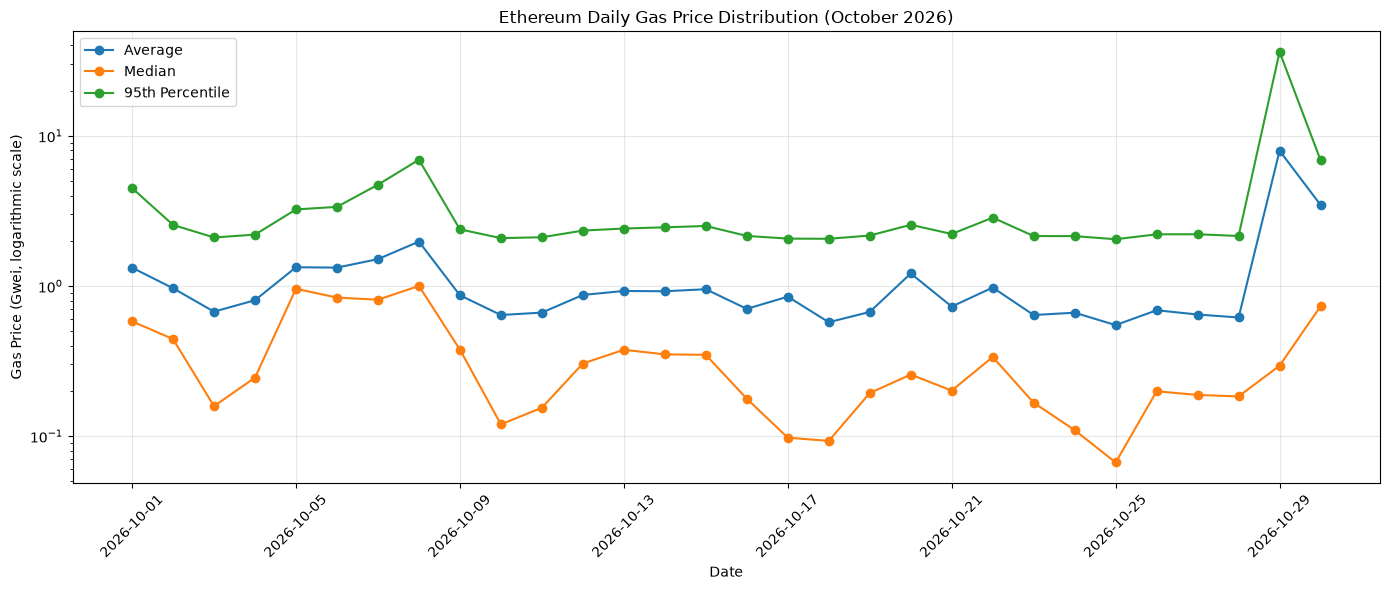

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(daily_gas_distribution["date"],
         daily_gas_distribution["avg_gas_price_gwei"],
         label="Average", marker="o")

plt.plot(daily_gas_distribution["date"],
         daily_gas_distribution["median_gas_price_gwei"],
         label="Median", marker="o")

plt.plot(daily_gas_distribution["date"],
         daily_gas_distribution["p95_gas_price_gwei"],
         label="95th Percentile", marker="o")

plt.yscale("log")
plt.title("Ethereum Daily Gas Price Distribution (October 2026)")
plt.xlabel("Date")
plt.ylabel("Gas Price (Gwei, logarithmic scale)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/05_daily_gas_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()